In [1]:
# Question: Which product categories sell a lot but get low review scores?
# Why? The SQL project ranked categories by revenue and, separately, by review score.
# Putting both on one chart shows where improving quality would affect the most customers.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from adjustText import adjust_text

customers = pd.read_csv('../csv_files/olist_customers_dataset.csv')
order_items = pd.read_csv('../csv_files/olist_order_items_dataset.csv')
orders = pd.read_csv('../csv_files/olist_orders_dataset.csv')
products = pd.read_csv('../csv_files/olist_products_dataset.csv')
payments = pd.read_csv('../csv_files/olist_order_payments_dataset.csv')
reviews = pd.read_csv('../csv_files/olist_order_reviews_dataset.csv')
geolocation = pd.read_csv('../csv_files/olist_geolocation_dataset.csv')
sellers = pd.read_csv('../csv_files/olist_sellers_dataset.csv')
category_translation = pd.read_csv('../csv_files/product_category_name_translation.csv')


# Initial exploration of the dataset structure, shape, and missing values before any cleaning. 
# Lines commented out below were used for inspection and are kept for reference.

#category_translation.head()
#customers.tail()
#customers.shape
#customers.describe()
#reviews.info()
#payments.isnull().sum()

print('orders:', orders.shape)
print('customers:', customers.shape)
print('order_items:', order_items.shape)
print('payments:', payments.shape)
print('reviews:', reviews.shape)
print('products:', products.shape)
print('category_translation:', category_translation.shape)

# Data cleanup: Convert all relevant date/time columns to datetime format

order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'])
reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'])
reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'])

date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

# Missing values in the tables that have them

print(orders.isnull().sum())
print(reviews.isnull().sum())
print(products.isnull().sum())

orders: (99441, 8)
customers: (99441, 5)
order_items: (112650, 7)
payments: (103886, 5)
reviews: (99224, 7)
products: (32951, 9)
category_translation: (71, 2)
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_

In [2]:
# Add the English category name to every item
items = order_items.merge(products[['product_id', 'product_category_name']], on='product_id', how='left')
items = items.merge(category_translation[['product_category_name', 'product_category_name_english']], on='product_category_name', how='left')

# Items without a category (or without a translation) are removed
items = items.dropna(subset='product_category_name_english')

In [3]:
# Add the review score to every item
# Some orders have more than one review, so average the score per order first.
review_per_order = reviews.groupby('order_id')['review_score'].mean().reset_index()
items = items.merge(review_per_order, on='order_id')

In [4]:
# Numbers per category: orders, revenue and average review score

df_category = items.groupby('product_category_name_english').agg(
    orders=('order_id', 'nunique'),
    revenue=('price', 'sum'),
    avg_review=('review_score', 'mean')
)

# Keep only categories with at least 100 orders, so the averages are reliable
df_category = df_category[df_category['orders'] >= 100]

overall_review = items['review_score'].mean()
print('Categories included:', len(df_category))
print('Overall average review score:', round(overall_review, 2))

Categories included: 51
Overall average review score: 4.04


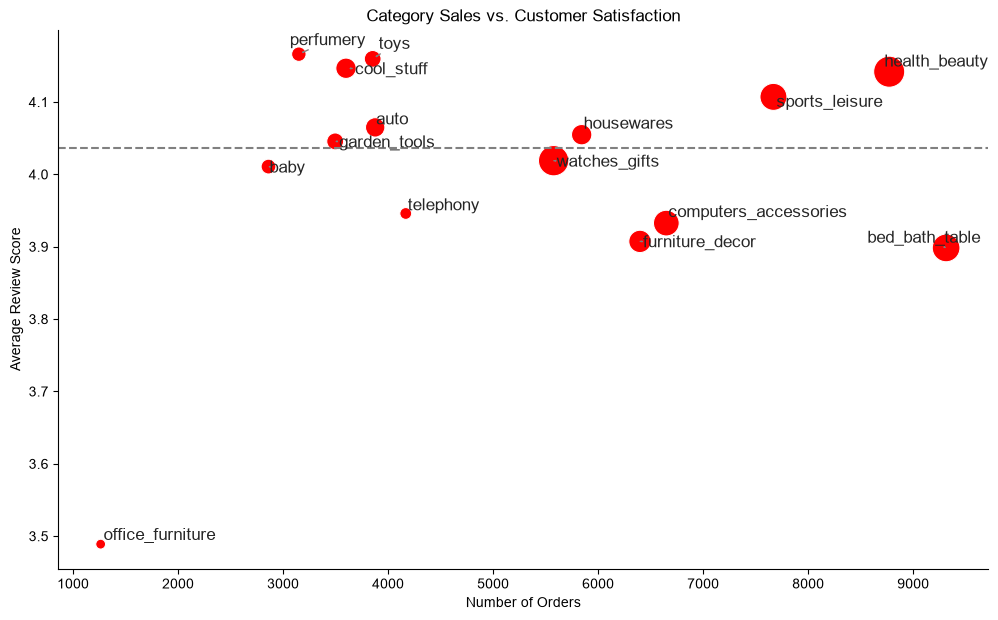

In [5]:
# Scatter plot: number of orders vs. average review score
# The chart shows the 15 categories with the highest revenue; bigger bubble = more revenue.

df_plot = df_category.sort_values(by='revenue', ascending=False).head(15)

plt.figure(figsize=(12, 7))
sns.scatterplot(data=df_plot, x='orders', y='avg_review', color='red', size='revenue', sizes=(50, 500), legend=False)
sns.despine()
sns.set_theme(style='ticks')

# Dashed line = overall average review score
plt.axhline(overall_review, color='gray', linestyle='--')

# Write the category name next to every bubble
text = []
for i, name in enumerate(df_plot.index):
    text.append(plt.text(df_plot['orders'].iloc[i], df_plot['avg_review'].iloc[i], name))

adjust_text(text, arrowprops=dict(arrowstyle='->', color='gray'))

plt.title('Category Sales vs. Customer Satisfaction')
plt.xlabel('Number of Orders')
plt.ylabel('Average Review Score')
plt.savefig('images/category_sales_vs_satisfaction.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# Priority categories: more orders than the median category, but a below-average review score

priority = df_category[(df_category['orders'] > df_category['orders'].median()) & (df_category['avg_review'] < overall_review)]
print('Median value of orders:', df_category['orders'].median())
print(priority.sort_values(by='revenue', ascending=False).round(2))

Median value of orders: 508.0
                               orders     revenue  avg_review
product_category_name_english                                
watches_gifts                    5576  1196495.83        4.02
bed_bath_table                   9313  1026192.38        3.90
computers_accessories            6649   906893.17        3.93
furniture_decor                  6398   723344.44        3.91
baby                             2861   408364.17        4.01
telephony                        4168   319939.20        3.95
office_furniture                 1263   271076.03        3.49
consoles_games                   1052   155371.27        4.02
